# Medicine stockout prediction

**Question:** for a store-drug that is in stock this week, will it stock out within the time it takes to restock (lead time + 1 week)?

- The target looks ahead over a lead-time-aware window, and only rows that are currently in stock are scored, so the model cannot win by saying "still out of stock".
- Features use only information available at the end of week *t* (cover, lags, rolling demand, orders in the pipeline, relevant disease signal).
- Train / validation / test are separated **by time**, with a gap so label windows do not overlap.
- The threshold is chosen on validation and reported once on test.
- Everything is compared with simple rule baselines. Accuracy is not reported.

**Data note:** the four CSVs in `data/` are synthetic. The panel is complete (16 stores x 19 drugs x 156 weeks) and orders arrive exactly on schedule, so results show how well the method recovers the simulated supply process, not how real pharmacies behave.

In [1]:
import os, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import average_precision_score, roc_auc_score, precision_recall_curve

warnings.filterwarnings('ignore', category=FutureWarning)
warnings.filterwarnings('ignore', category=DeprecationWarning)
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)

In [2]:
# ---------------- config ----------------
DATA_DIR = os.environ.get('MEDSTOCK_DATA', 'data')   # folder holding the four CSVs
KEYS = ['store_id', 'drug_id']
WARMUP_WEEKS = 12          # early weeks have too little history for rolling features
HORIZON_EXTRA = 1          # primary target window = supplier lead time + this many weeks
ONLY_IN_STOCK = True       # score only rows that are in stock at week t
TRAIN_FRAC, VAL_FRAC = 0.60, 0.20   # remaining ~20% of weeks is the test period
BETA = 2                   # F-beta used to pick the alert threshold (2 = recall counts double)
SEED = 42

In [3]:
dispensing = pd.read_csv(os.path.join(DATA_DIR, 'dispensing.csv'))
context    = pd.read_csv(os.path.join(DATA_DIR, 'context.csv'))
drugs      = pd.read_csv(os.path.join(DATA_DIR, 'drugs.csv'))
stores     = pd.read_csv(os.path.join(DATA_DIR, 'stores.csv'))
for n, d in [('dispensing', dispensing), ('context', context), ('drugs', drugs), ('stores', stores)]:
    print(f'{n:11s}', d.shape)

dispensing  (47424, 20)
context     (1248, 15)
drugs       (19, 7)
stores      (16, 7)


## 1. Build the base table

Only operational columns are kept. Columns such as `dispense_status`, prescriber, patient or payment fields are left out on purpose: they are either irrelevant or describe the outcome of the week itself.

In [4]:
disp = dispensing[KEYS + ['region', 'week', 'demand', 'units_dispensed',
                          'stock_on_hand', 'units_ordered', 'stockout']].copy()

ctx = context.drop(columns=[c for c in ['date'] if c in context.columns]).sort_values(['region', 'week']).copy()
sev_cols = [c for c in ctx.columns if c.startswith('sev_')]
for c in sev_cols:   # change in severity over 2 weeks: a rising signal matters more than the level
    ctx[c + '_chg2'] = ctx.groupby('region')[c].diff(2).fillna(0)
ctx['rain_roll4'] = ctx.groupby('region')['rainfall_anomaly'].transform(lambda s: s.rolling(4, min_periods=1).mean())

n0 = len(disp)
df = (disp
      .merge(stores[['store_id', 'catchment_population', 'supplier_lead_time_weeks']], on='store_id', how='left', validate='m:1')
      .merge(drugs[['drug_id', 'name', 'category', 'baseline_weekly_demand', 'shelf_life_weeks',
                    'seasonal_amplitude', 'responds_to']].rename(columns={'name': 'drug_name'}),
             on='drug_id', how='left', validate='m:1')
      .merge(ctx, on=['region', 'week'], how='left', validate='m:1'))
assert len(df) == n0, 'merge changed the number of rows'
assert df[['supplier_lead_time_weeks', 'baseline_weekly_demand', 'week_of_year']].notna().all().all(), 'unmatched keys after merge'

df = df.sort_values(KEYS + ['week']).reset_index(drop=True)
df['series'] = df['store_id'] + '|' + df['drug_id']

# the panel must be complete: one row per store-drug-week, no gaps (shift() relies on it)
gaps = df.groupby('series')['week'].apply(lambda s: (s.diff().dropna() != 1).sum()).sum()
assert gaps == 0, f'{gaps} gaps in weekly series'

print(df.shape, '| series:', df['series'].nunique(), '| weeks:', df['week'].nunique())
print('stockout rate (all rows):', round(df['stockout'].mean(), 4))
print('lead times:', df['supplier_lead_time_weeks'].value_counts().sort_index().to_dict())

(47424, 39) | series: 304 | weeks: 156
stockout rate (all rows): 0.0081
lead times: {1: 23712, 2: 17784, 3: 5928}


### Check how stock moves

The features assume `stock_on_hand` is the stock at the **start** of the week, so next week's stock is `stock - dispensed + arrivals`. The cell below tests this and shows when orders arrive.

Result: the identity holds in every row, and each arrival equals the order placed `lead - 1` weeks earlier. So the orders still in transit at the end of week *t* are the ones placed in weeks *t-lead+1 ... t*, which is the window used for `orders_in_window` below.

In [5]:
g = df.groupby('series', sort=False)
arrivals = g['stock_on_hand'].shift(-1) - (df['stock_on_hand'] - df['units_dispensed'])
print('arrivals < 0 (identity broken):', round((arrivals < 0).mean(), 4), '| arrivals > 0:', round((arrivals > 0).mean(), 4))

rows = []
for L in sorted(df['supplier_lead_time_weeks'].unique()):
    m = df['supplier_lead_time_weeks'] == L
    for lag in [L - 1, L, L + 1]:
        if lag < 0: continue
        o = g['units_ordered'].shift(lag)
        ok = m & (arrivals > 0) & o.notna()
        rows.append(dict(lead=L, order_lag=lag, share_of_arrivals_matching_order=round((arrivals[ok] == o[ok]).mean(), 3)))
print(pd.DataFrame(rows).to_string(index=False))
print('\nresponds_to values:', sorted(df['responds_to'].astype(str).unique()))
print('sev columns:', sev_cols)

arrivals < 0 (identity broken): 0.0 | arrivals > 0: 0.3287
 lead  order_lag  share_of_arrivals_matching_order
    1          0                             1.000
    1          1                             0.000
    1          2                             0.002
    2          1                             1.000
    2          2                             0.000
    2          3                             0.003
    3          2                             1.000
    3          3                             0.000
    3          4                             0.000

responds_to values: ['dengue;diarrhoeal;typhoid', 'dengue;flu;chikungunya;typhoid', 'diarrhoeal', 'flu', 'flu;respiratory', 'leptospirosis', 'malaria', 'none', 'respiratory', 'respiratory;typhoid']
sev columns: ['sev_dengue', 'sev_malaria', 'sev_flu', 'sev_diarrhoeal', 'sev_respiratory', 'sev_typhoid', 'sev_chikungunya', 'sev_leptospirosis']


## 2. Features (only what is known at the end of week *t*)

In [6]:
def add_features(d):
    d = d.copy()
    G = lambda col: d.groupby('series', sort=False)[col]
    roll = lambda col, w, fn: G(col).transform(lambda s: s.rolling(w, min_periods=1).agg(fn))
    lead = d['supplier_lead_time_weeks']

    # demand history
    d['demand_lag1'] = G('demand').shift(1).fillna(d['demand'])
    d['demand_roll4_mean'] = roll('demand', 4, 'mean')
    d['demand_roll4_std'] = roll('demand', 4, 'std').fillna(0)
    d['demand_roll12_mean'] = roll('demand', 12, 'mean')
    d['demand_trend'] = d['demand_roll4_mean'] / d['demand_roll12_mean'].clip(lower=1)
    d['demand_cv'] = d['demand_roll4_std'] / d['demand_roll4_mean'].clip(lower=1)
    d['demand_vs_baseline'] = d['demand'] / d['baseline_weekly_demand'].clip(lower=1)
    d['fill_rate'] = d['units_dispensed'] / d['demand'].clip(lower=1)

    # stock cover: how many weeks of demand the stock lasts
    rate = d['demand_roll4_mean'].clip(lower=1)
    d['stock_after_dispensing'] = d['stock_on_hand'] - d['units_dispensed']
    d['cover_weeks'] = (d['stock_on_hand'] / rate).clip(upper=52)
    d['projected_cover_weeks'] = (d['stock_after_dispensing'] / rate).clip(upper=52)
    d['cover_minus_lead'] = d['projected_cover_weeks'] - lead

    # orders placed in the last `lead` weeks (probably not arrived yet)
    inflight = np.zeros(len(d))
    for k in range(int(lead.max())):
        inflight += np.where(k < lead.values, G('units_ordered').shift(k).fillna(0).values, 0)
    d['orders_in_window'] = inflight
    d['pipeline_cover_weeks'] = ((d['stock_after_dispensing'] + inflight) / rate).clip(upper=52)

    # stockout history
    d['stockouts_last_4'] = roll('stockout', 4, 'sum')
    d['stockouts_last_12'] = roll('stockout', 12, 'sum')
    last = d['week'].where(d['stockout'] == 1)
    last = last.groupby(d['series']).ffill()
    d['weeks_since_stockout'] = (d['week'] - last).fillna(52).clip(upper=52)

    # seasonality
    d['week_sin'] = np.sin(2 * np.pi * d['week_of_year'] / 52)
    d['week_cos'] = np.cos(2 * np.pi * d['week_of_year'] / 52)

    # disease signal for the diseases this drug treats; responds_to can list several, e.g. "flu;respiratory"
    diseases = d['responds_to'].astype(str).str.lower().str.split(';')
    sev = np.full(len(d), np.nan)
    chg = np.full(len(d), np.nan)
    for c in sev_cols:
        name = c.replace('sev_', '')
        m = diseases.apply(lambda lst: name in lst).values
        sev[m] = np.fmax(sev[m], d.loc[m, c].values)                    # strongest signal among the listed diseases
        chg[m] = np.fmax(chg[m], d.loc[m, c + '_chg2'].values)
    d['relevant_sev'] = np.nan_to_num(sev)                              # 0 for drugs with responds_to == "none"
    d['relevant_sev_chg2'] = np.nan_to_num(chg)
    has_link = (d['responds_to'].astype(str).str.lower() != 'none').values
    print(f'non-"none" rows with a matched disease signal: {(~np.isnan(sev[has_link])).mean():.0%}')

    return pd.get_dummies(d, columns=['monsoon_phase', 'category'], dtype=float)

feat = add_features(df)

NUMERIC = ['demand', 'units_dispensed', 'stock_on_hand', 'units_ordered', 'stock_after_dispensing',
           'demand_lag1', 'demand_roll4_mean', 'demand_roll4_std', 'demand_roll12_mean', 'demand_trend',
           'demand_cv', 'demand_vs_baseline', 'fill_rate',
           'cover_weeks', 'projected_cover_weeks', 'cover_minus_lead', 'orders_in_window', 'pipeline_cover_weeks',
           'stockouts_last_4', 'stockouts_last_12', 'weeks_since_stockout',
           'supplier_lead_time_weeks', 'catchment_population', 'baseline_weekly_demand', 'shelf_life_weeks',
           'seasonal_amplitude', 'week_sin', 'week_cos',
           'rainfall_anomaly', 'rain_roll4', 'festival_intensity', 'relevant_sev', 'relevant_sev_chg2'] + sev_cols
DUMMIES = [c for c in feat.columns if c.startswith('monsoon_phase_') or c.startswith('category_')]
FEATURES = NUMERIC + DUMMIES
assert not {'stockout', 'target', 'store_id', 'drug_id', 'series'} & set(FEATURES)
print(len(FEATURES), 'features')

non-"none" rows with a matched disease signal: 100%
64 features


## 3. Target, time split and evaluation helpers

`target = 1` if the store-drug has at least one stockout in weeks *t+1 ... t+H*, where `H = lead time + 1`. Rows whose full window runs past the end of the data are dropped, not labelled 0.

In [7]:
def build_dataset(mode):
    d = feat.copy()
    H = pd.Series(1, index=d.index) if mode == 'fixed1' else d['supplier_lead_time_weeks'] + HORIZON_EXTRA
    G = d.groupby('series', sort=False)['stockout']
    future, valid = np.zeros(len(d)), np.ones(len(d), dtype=bool)
    for k in range(1, int(H.max()) + 1):
        s = G.shift(-k)
        within = (k <= H).values
        future = np.where(within & (s == 1).values, 1, future)
        valid &= ~(within & s.isna().values)
    d['target'], d['horizon'] = future.astype(int), H
    d = d[valid & (d['week'] >= WARMUP_WEEKS)]
    if ONLY_IN_STOCK:
        d = d[d['stockout'] == 0]
    return d.reset_index(drop=True)


def time_split(d, gap):
    weeks = np.sort(d['week'].unique())
    t_end = weeks[int(len(weeks) * TRAIN_FRAC) - 1]
    v_start, v_end = t_end + gap + 1, weeks[int(len(weeks) * (TRAIN_FRAC + VAL_FRAC)) - 1]
    te_start = v_end + gap + 1
    tr = d['week'] <= t_end
    va = d['week'].between(v_start, v_end)
    te = d['week'] >= te_start
    print(f'train weeks <= {t_end} | val {v_start}-{v_end} | test >= {te_start}  (gap {gap} weeks)')
    return tr.values, va.values, te.values


def pick_threshold(y, p, beta=BETA):
    prec, rec, thr = precision_recall_curve(y, p)
    prec, rec = prec[:-1], rec[:-1]
    f = (1 + beta**2) * prec * rec / (beta**2 * prec + rec + 1e-12)
    return thr[np.argmax(f)]


def at_threshold(y, p, thr):
    y = np.asarray(y); pred = np.asarray(p) >= thr
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum()); fn = int((~pred & (y == 1)).sum())
    return dict(threshold=round(float(thr), 4), alerts=int(pred.sum()), tp=tp, fp=fp, fn=fn,
                precision=round(tp / max(tp + fp, 1), 3), recall=round(tp / max(tp + fn, 1), 3))


def recall_at_top(y, p, fracs=(0.02, 0.05, 0.10)):
    y, p = np.asarray(y), np.asarray(p)
    order = np.argsort(-p)
    return {f'top {int(f*100)}%': round(float(y[order[:max(int(f * len(p)), 1)]].sum() / max(y.sum(), 1)), 3) for f in fracs}


def group_bootstrap_ap(y, p, groups, n=300, seed=0):
    rng = np.random.default_rng(seed)
    y, p = np.asarray(y), np.asarray(p)
    idx = {g: np.where(groups == g)[0] for g in np.unique(groups)}
    keys = list(idx)
    out = []
    for _ in range(n):
        take = np.concatenate([idx[k] for k in rng.choice(keys, len(keys))])
        if y[take].sum() > 0:
            out.append(average_precision_score(y[take], p[take]))
    return np.percentile(out, [2.5, 97.5])

## 4. Baselines and models

Baselines are one-line rules with no training. A model only earns its place if it beats them on the **test** period.

In [8]:
def make_models():
    return {
        'LogReg': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                LogisticRegression(class_weight='balanced', C=0.5, max_iter=3000)),
        'RandomForest': RandomForestClassifier(n_estimators=300, min_samples_leaf=5, max_features='sqrt',
                                               class_weight='balanced_subsample', n_jobs=-1, random_state=SEED),
        'HistGB': HistGradientBoostingClassifier(max_depth=4, learning_rate=0.05, max_iter=250,
                                                 l2_regularization=1.0, class_weight='balanced', random_state=SEED),
    }

BASELINES = {
    'rule: low projected cover':   lambda d: -d['projected_cover_weeks'].values,
    'rule: cover below lead time': lambda d: -d['cover_minus_lead'].values,
    'rule: pipeline cover below lead time': lambda d: -(d['pipeline_cover_weeks'].values - d['supplier_lead_time_weeks'].values),
    'rule: recent stockouts':      lambda d: d['stockouts_last_12'].values - 0.001 * d['weeks_since_stockout'].values,
}


def run_experiment(mode):
    d = build_dataset(mode)
    tr, va, te = time_split(d, gap=int(d['horizon'].max()))
    y = d['target'].values
    print(f'[{mode}] rows train/val/test = {tr.sum()}/{va.sum()}/{te.sum()} | '
          f'positives = {y[tr].sum()}/{y[va].sum()}/{y[te].sum()} | '
          f'base rate test = {y[te].mean():.4f}')
    if y[va].sum() < 30 or y[te].sum() < 30:
        print('WARNING: fewer than 30 positives in val or test, so treat all numbers as very noisy.')

    X = d[FEATURES]
    rows, preds, fitted = [], {}, {}
    for name, fn in BASELINES.items():
        pv, pt = fn(d[va]), fn(d[te])
        preds[name] = (pv, pt)
        rows.append(dict(model=name, val_PR_AUC=average_precision_score(y[va], pv),
                         test_PR_AUC=average_precision_score(y[te], pt), test_ROC_AUC=roc_auc_score(y[te], pt)))
    for name, m in make_models().items():
        m.fit(X[tr], y[tr])
        pv, pt = m.predict_proba(X[va])[:, 1], m.predict_proba(X[te])[:, 1]
        preds[name], fitted[name] = (pv, pt), m
        rows.append(dict(model=name, val_PR_AUC=average_precision_score(y[va], pv),
                         test_PR_AUC=average_precision_score(y[te], pt), test_ROC_AUC=roc_auc_score(y[te], pt)))
    table = pd.DataFrame(rows).round(3)
    return dict(d=d, X=X, y=y, tr=tr, va=va, te=te, preds=preds, fitted=fitted, table=table)


## 5. Results

`lead+1` is the main setting. `fixed1` (next week only, still excluding rows already out of stock) is shown for comparison.

In [9]:
res = {}
for mode in ['lead+1', 'fixed1']:
    print('=' * 20, mode, '=' * 20)
    res[mode] = run_experiment(mode)
    print(res[mode]['table'].to_string(index=False))
    print('(a random score would give PR-AUC equal to the base rate)\n')

==================== lead+1 ====================
train weeks <= 96 | val 101-124 | test >= 129  (gap 4 weeks)
[lead+1] rows train/val/test = 25653/7235/7309 | positives = 520/171/237 | base rate test = 0.0324


                               model  val_PR_AUC  test_PR_AUC  test_ROC_AUC
           rule: low projected cover       0.110        0.133         0.802
         rule: cover below lead time       0.267        0.255         0.888
rule: pipeline cover below lead time       0.198        0.219         0.810
              rule: recent stockouts       0.098        0.178         0.780
                              LogReg       0.329        0.518         0.934
                        RandomForest       0.372        0.532         0.943
                              HistGB       0.383        0.554         0.937
(a random score would give PR-AUC equal to the base rate)

==================== fixed1 ====================
train weeks <= 96 | val 98-125 | test >= 127  (gap 1 weeks)
[fixed1] rows train/val/test = 25653/8443/8402 | positives = 178/63/104 | base rate test = 0.0124


                               model  val_PR_AUC  test_PR_AUC  test_ROC_AUC
           rule: low projected cover       0.081        0.082         0.888
         rule: cover below lead time       0.193        0.165         0.906
rule: pipeline cover below lead time       0.102        0.106         0.893
              rule: recent stockouts       0.031        0.079         0.771
                              LogReg       0.169        0.225         0.939
                        RandomForest       0.323        0.472         0.960
                              HistGB       0.322        0.489         0.958
(a random score would give PR-AUC equal to the base rate)



## 6. Main model: threshold from validation, one look at test

best model on validation PR-AUC: HistGB

validation (threshold chosen here): {'threshold': 0.3938, 'alerts': 599, 'tp': 124, 'fp': 475, 'fn': 47, 'precision': 0.207, 'recall': 0.725}
test: {'threshold': 0.3938, 'alerts': 913, 'tp': 198, 'fp': 715, 'fn': 39, 'precision': 0.217, 'recall': 0.835}
test recall if staff review only the top-scored rows: {'top 2%': 0.388, 'top 5%': 0.633, 'top 10%': 0.793}


test PR-AUC 0.554  (95% CI 0.418 to 0.658, resampling store-drug series)
best rule on validation: "rule: cover below lead time" -> test PR-AUC 0.255


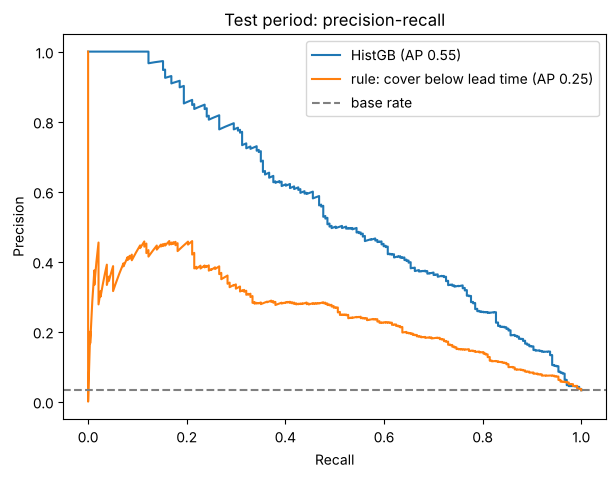

In [10]:
R = res['lead+1']
d, y, va, te = R['d'], R['y'], R['va'], R['te']
models_only = [m for m in R['fitted']]
best = max(models_only, key=lambda m: average_precision_score(y[va], R['preds'][m][0]))
pv, pt = R['preds'][best]
thr = pick_threshold(y[va], pv)
print('best model on validation PR-AUC:', best)

print('\nvalidation (threshold chosen here):', at_threshold(y[va], pv, thr))
print('test:', at_threshold(y[te], pt, thr))
print('test recall if staff review only the top-scored rows:', recall_at_top(y[te], pt))

lo, hi = group_bootstrap_ap(y[te], pt, d.loc[te, 'series'].values)
print(f'test PR-AUC {average_precision_score(y[te], pt):.3f}  (95% CI {lo:.3f} to {hi:.3f}, resampling store-drug series)')
best_rule = max(BASELINES, key=lambda m: average_precision_score(y[va], R['preds'][m][0]))
print(f'best rule on validation: "{best_rule}" -> test PR-AUC {average_precision_score(y[te], R["preds"][best_rule][1]):.3f}')

fig, ax = plt.subplots(figsize=(7, 5))
for name in [best, best_rule]:
    p, r, _ = precision_recall_curve(y[te], R['preds'][name][1])
    ax.plot(r, p, label=f'{name} (AP {average_precision_score(y[te], R["preds"][name][1]):.2f})')
ax.axhline(y[te].mean(), ls='--', c='grey', label='base rate')
ax.set_xlabel('Recall'); ax.set_ylabel('Precision'); ax.set_title('Test period: precision-recall'); ax.legend()
plt.show()

In [11]:
# does the score only reflect the length of the window? (window = lead time + 1, so longer lead = more positives)
t = d[te].copy()
t['score'] = pt
t['rule'] = R['preds'][best_rule][1]
rows = []
for L, g in t.groupby('supplier_lead_time_weeks'):
    rows.append(dict(lead_time_weeks=L, window_weeks=L + HORIZON_EXTRA, rows=len(g), positives=int(g['target'].sum()),
                     base_rate=round(g['target'].mean(), 4),
                     model_PR_AUC=round(average_precision_score(g['target'], g['score']), 3),
                     best_rule_PR_AUC=round(average_precision_score(g['target'], g['rule']), 3)))
print(pd.DataFrame(rows).to_string(index=False))

n_weeks = t['week'].nunique()
alerts = int((pt >= thr).sum())
print(f"\ntest weeks: {n_weeks} | alerts: {alerts} ({alerts / len(t):.1%} of scored rows) "
      f"= {alerts / n_weeks:.0f} per week across {d['store_id'].nunique()} stores "
      f"| false alarms per true catch: {at_threshold(y[te], pt, thr)['fp'] / max(at_threshold(y[te], pt, thr)['tp'], 1):.1f}")

 lead_time_weeks  window_weeks  rows  positives  base_rate  model_PR_AUC  best_rule_PR_AUC
               1             2  3790         21     0.0055         0.051             0.035
               2             3  2696         91     0.0338         0.496             0.158
               3             4   823        125     0.1519         0.668             0.342

test weeks: 25 | alerts: 913 (12.5% of scored rows) = 37 per week across 16 stores | false alarms per true catch: 3.6


In [12]:
# what drives the predictions (validation period, permutation importance on PR-AUC)
m = R['fitted'][best]
Xv, yv = R['X'][va], y[va]
imp = permutation_importance(m, Xv, yv, scoring='average_precision', n_repeats=5, random_state=SEED, n_jobs=-1)
imp = pd.Series(imp.importances_mean, index=FEATURES).sort_values(ascending=False)
print(imp.head(15).round(4).to_string())

cover_minus_lead            0.2228
supplier_lead_time_weeks    0.1304
relevant_sev                0.0856
demand_trend                0.0567
catchment_population        0.0332
units_ordered               0.0211
seasonal_amplitude          0.0156
orders_in_window            0.0123
weeks_since_stockout        0.0116
pipeline_cover_weeks        0.0088
demand_vs_baseline          0.0080
stockouts_last_12           0.0034
category_Rehydration        0.0024
category_Supplement         0.0022
baseline_weekly_demand      0.0021


In [13]:
# where does it fail? test period, by drug
t = d[te].copy()
t['score'], t['alert'] = pt, (pt >= thr)
by_drug = (t.groupby('drug_name')
             .apply(lambda x: pd.Series(dict(rows=len(x), stockout_events=int(x['target'].sum()),
                                             caught=int((x['alert'] & (x['target'] == 1)).sum()),
                                             false_alarms=int((x['alert'] & (x['target'] == 0)).sum()))))
             .assign(recall=lambda x: (x['caught'] / x['stockout_events'].replace(0, np.nan)).round(2))
             .sort_values('stockout_events', ascending=False))
print(by_drug.head(15).to_string())

                                  rows  stockout_events  caught  false_alarms  recall
drug_name                                                                            
Paracetamol 500mg                  362               54      48            89    0.89
Artemether+Lumefantrine 20/120mg   363               50      49            83    0.98
Doxycycline 100mg                  373               48      36            51    0.75
ORS (WHO formula)                  380               28      24           138    0.86
Atorvastatin 10mg                  387                8       5            10    0.62
Levothyroxine 50mcg                388                8       6            12    0.75
Azithromycin 500mg                 387                7       6            51    0.86
Zinc Dispersible 20mg              387                6       6            86    1.00
Pantoprazole 40mg                  388                6       4            10    0.67
Oseltamivir 75mg                   389                

## 7. Conclusions

Numbers below come from the run saved in this notebook.

- **Model vs rules.** On the test period the best model (HistGB, PR-AUC 0.55, 95% CI 0.42 to 0.66) is about twice as good as the best rule ("cover below lead time", 0.26). A random score would give 0.03. The three models (0.52, 0.53, 0.55) are closer to each other than the uncertainty allows, so no ranking among them is claimed.
- **Lead time.** The window is lead time + 1, so the base rate rises with lead time: 0.6%, 3.4% and 15.2% for lead times of 1, 2 and 3 weeks. The pooled PR-AUC is helped by the lead-3 stores, which hold 53% of the test positives (125 of 237). Within each lead time the model still beats the best rule at lead 2 (0.50 vs 0.16) and lead 3 (0.67 vs 0.34). At lead 1 there are only 21 test positives and the model is weak in absolute terms (0.05).
- **Alert load.** At the validation threshold the model raised 913 alerts over 25 test weeks (37 a week across 16 stores, 12.5% of in-stock rows) and caught 198 of 237 events: recall 0.84, precision 0.22, about 3.6 false alarms per catch. Recall was 0.73 on validation, so plan for a value between the two rather than the test figure.
- **Where it misses.** Four drugs carry 76% of the test events (180 of 237). Recall for the other drugs rests on 1 to 8 events each and is not a stable rate. Telmisartan (0 of 3) and Amlodipine (1 of 4) are the clearest misses.
- **Limits.** The data is synthetic, so scores reflect the simulated supply process. The test window is 25 weeks, under half a seasonal cycle. The features use true demand, which real dispensing records do not contain: they show units dispensed, so demand is censored whenever stock runs out.

## 8. Recall by drug category and by drug

Recall is only meaningful where there are enough stockout events. Bars show the event count (n); categories with fewer than 10 events are drawn in grey and should not be read as a rate.

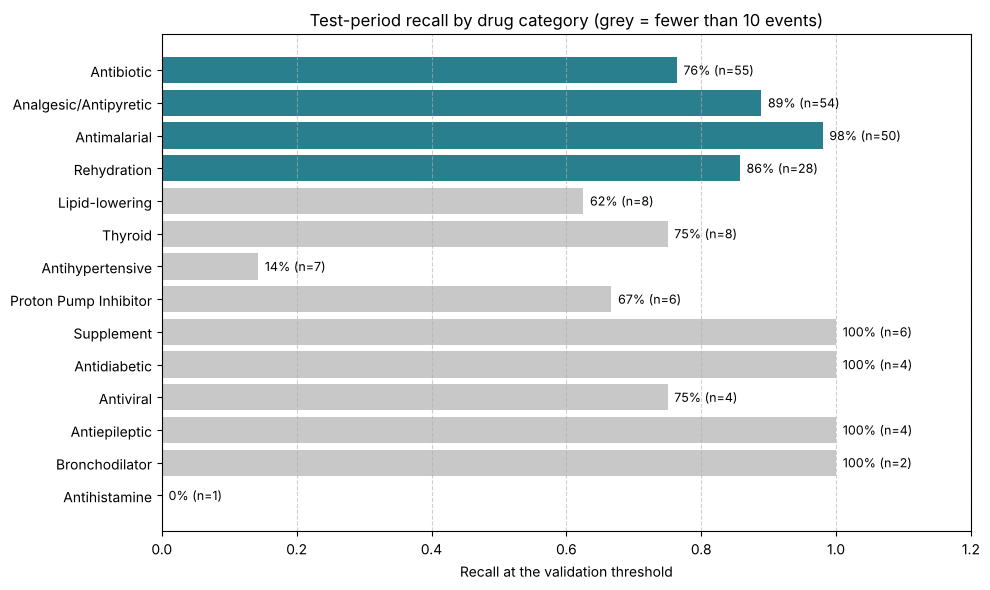

,category,stockout_events,caught,recall
1,Antibiotic,55,42,0.76
0,Analgesic/Antipyretic,54,48,0.89
6,Antimalarial,50,49,0.98
12,Rehydration,28,24,0.86
10,Lipid-lowering,8,5,0.62
14,Thyroid,8,6,0.75
5,Antihypertensive,7,1,0.14
11,Proton Pump Inhibitor,6,4,0.67
13,Supplement,6,6,1.00
2,Antidiabetic,4,4,1.00


In [14]:
# 'category' was one-hot encoded during preprocessing, so merge it back from drugs.csv
t_eval = d[te].copy()
t_eval['alert'] = (pt >= thr)
t_eval = t_eval.merge(drugs[['drug_id', 'category']], on='drug_id', how='left')

by_cat = (t_eval.groupby('category')
          .apply(lambda x: pd.Series({'stockout_events': int(x['target'].sum()),
                                      'caught': int((x['alert'] & (x['target'] == 1)).sum())}))
          .reset_index())
by_cat = by_cat[by_cat['stockout_events'] > 0].copy()
by_cat['recall'] = by_cat['caught'] / by_cat['stockout_events']
by_cat = by_cat.sort_values('stockout_events', ascending=False)

MIN_EVENTS = 10
colors = ['#2a7f8e' if n >= MIN_EVENTS else '#c8c8c8' for n in by_cat['stockout_events']]
fig, ax = plt.subplots(figsize=(10, 6))
ax.barh(by_cat['category'], by_cat['recall'], color=colors)
for y_pos, (r, n) in enumerate(zip(by_cat['recall'], by_cat['stockout_events'])):
    ax.text(r + 0.01, y_pos, f'{r:.0%} (n={n})', va='center', fontsize=9)
ax.invert_yaxis()
ax.set_xlim(0, 1.2)
ax.set_xlabel('Recall at the validation threshold')
ax.set_title(f'Test-period recall by drug category (grey = fewer than {MIN_EVENTS} events)')
ax.grid(axis='x', linestyle='--', alpha=0.6)
plt.tight_layout()
plt.show()

display(by_cat.round({'recall': 2}))

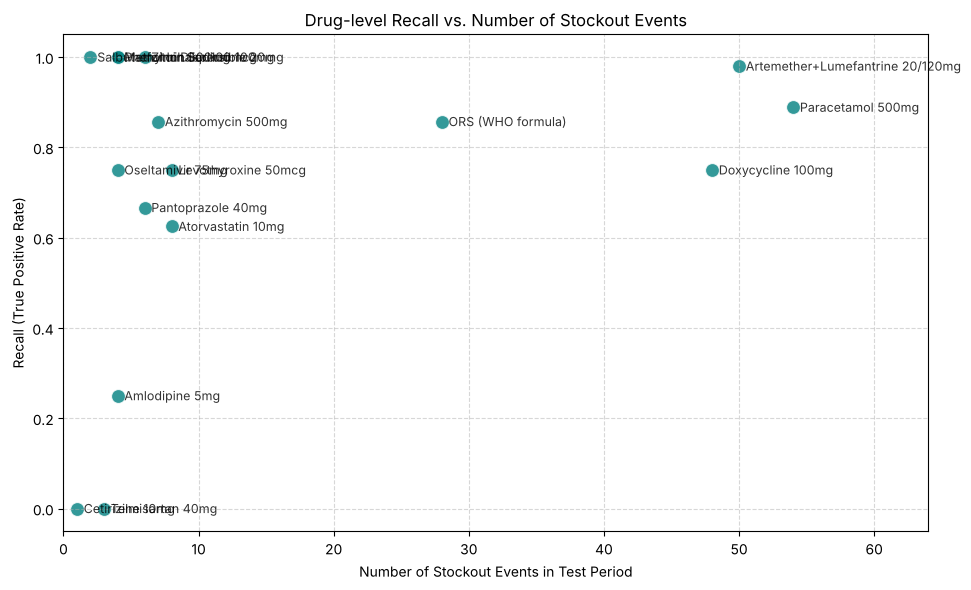

In [15]:
import seaborn as sns

# Prepare the data mapping back drug names to test predictions
t_drug = d[te].copy()
t_drug['score'] = pt
t_drug['alert'] = (pt >= thr)

# Group by drug_name and calculate metrics
by_drug_stats = (t_drug.groupby('drug_name')
                 .apply(lambda x: pd.Series({
                     'stockout_events': int(x['target'].sum()),
                     'caught': int((x['alert'] & (x['target'] == 1)).sum())
                 }))
                 .reset_index())

# Only consider drugs with at least one stockout event
by_drug_stats = by_drug_stats[by_drug_stats['stockout_events'] > 0].copy()
by_drug_stats['recall'] = by_drug_stats['caught'] / by_drug_stats['stockout_events']

# Create scatter plot
plt.figure(figsize=(10, 6))
sns.scatterplot(data=by_drug_stats, x='stockout_events', y='recall', s=100, color='teal', alpha=0.8)

# Annotate each point with the drug's name
for _, row in by_drug_stats.iterrows():
    plt.text(row['stockout_events'] + 0.5, row['recall'], row['drug_name'],
             fontsize=9, verticalalignment='center', alpha=0.8)

plt.title('Drug-level Recall vs. Number of Stockout Events')
plt.xlabel('Number of Stockout Events in Test Period')
plt.ylabel('Recall (True Positive Rate)')
plt.xlim(0, by_drug_stats['stockout_events'].max() + 10)
plt.ylim(-0.05, 1.05)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()